# Prévoir 24 heures de demande électrique avec un LSTM
## Projet complet en français — données UCI, PyTorch, références et test chronologique

**Objectif :** prévoir les 24 puissances horaires moyennes de demain à partir de
168 heures d'historique. Nous comparons un vrai réseau LSTM à la répétition des profils
quotidiens et hebdomadaires et à Ridge. L'entraînement utilise 2012, la validation 2013
et le test final 2014. Trois graines évaluent la variabilité et une ablation compare
24 à 168 heures d'historique. Aucun résultat favorable au réseau n'est présupposé.

**Exécution :** Python 3.12, Jupyter ou Colab, « Restart & Run All ». Conserver le
dossier `donnees` à côté du notebook et lancer Jupyter dans ce dossier de projet.
L'extrait fourni évite de retélécharger l'archive UCI de 249 Mo. Si absent, la cellule
d'acquisition la télécharge et extrait les dix premiers clients. Prévoir environ 1 Go
d'espace libre pour cette première récupération ; aucun GPU n'est nécessaire.
Les résultats et checkpoints sont écrits dans `resultats`.

**Source :** [UCI ElectricityLoadDiagrams20112014](https://archive.ics.uci.edu/dataset/321/electricityloaddiagrams20112014),
Artur Trindade (2015), [DOI 10.24432/C58C86](https://doi.org/10.24432/C58C86), licence CC BY 4.0.
Les mesures sont réelles, mais anonymisées : ne pas attribuer le client à un campus.


In [1]:
import sys, subprocess
from importlib.util import find_spec
packages={'numpy':'numpy>=1.26,<3','pandas':'pandas==3.0.1',
          'sklearn':'scikit-learn==1.7.2','matplotlib':'matplotlib==3.10.7',
          'torch':'torch==2.7.1','threadpoolctl':'threadpoolctl>=3.5,<4'}
missing=[spec for module,spec in packages.items() if find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install',*missing])
print('Bibliothèques disponibles ; PyTorch peut nécessiter plusieurs centaines de Mo.')


Bibliothèques disponibles ; PyTorch peut nécessiter plusieurs centaines de Mo.


In [2]:
from pathlib import Path
import json, hashlib, time, platform, warnings, copy, random, calendar
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
DATA, OUT = Path('donnees'), Path('resultats')
DATA.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.2,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
def sha256(path):
    with Path(path).open('rb') as f: return hashlib.file_digest(f,'sha256').hexdigest()
def savefig(fig,name):
    fig.savefig(OUT/name,dpi=160,bbox_inches='tight'); plt.show()
def scores(y,p):
    y,p=np.asarray(y).ravel(),np.asarray(p).ravel()
    return dict(MAE=mean_absolute_error(y,p),RMSE=np.sqrt(mean_squared_error(y,p)),biais=np.mean(p-y))

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
torch.set_num_threads(2)
try: torch.set_num_interop_threads(1)
except RuntimeError: pass
torch.use_deterministic_algorithms(True)
DEVICE='cpu'
SEEDS=(17,42,73)
CFG=dict(hidden=32,epochs=80,patience=12,batch_size=32,learning_rate=.003,weight_decay=1e-4)
versions={p:version(p) for p in ('numpy','pandas','scikit-learn','matplotlib','torch')}
display(pd.Series(versions,name='Version'))


numpy               2.5.4
pandas              3.0.1
scikit-learn        1.7.2
matplotlib         3.10.7
torch           2.7.1+cpu
Name: Version, dtype: str

### 1. Acquisition vérifiable et choix du client sur l'entraînement

L'extrait conserve les dix premières colonnes de clients, sans sélection sur leurs
résultats futurs. Le client retenu est le premier identifiant dont au moins 95 % des
valeurs de **2012** sont positives et dont la série n'est pas constante. Cette règle
évite les clients encore inactifs, sans rechercher après coup le meilleur score.
L'empreinte du fichier livré est contrôlée ; le manifeste conserve aussi l'archive d'origine.


In [3]:
import urllib.request, zipfile
archive=DATA/'electricityloaddiagrams20112014.zip'
subset=DATA/'uci_10_clients_15min.csv.gz'
manifest_path=DATA/'provenance_uci.json'
UCI_URL='https://archive.ics.uci.edu/static/public/321/electricityloaddiagrams20112014.zip'
if not subset.exists():
    if not archive.exists():
        print('Téléchargement UCI (~249 Mo)…',flush=True)
        with urllib.request.urlopen(UCI_URL,timeout=180) as r, archive.with_suffix('.part').open('wb') as f:
            while chunk:=r.read(1024*1024): f.write(chunk)
        archive.with_suffix('.part').replace(archive)
    with zipfile.ZipFile(archive) as z:
        member=next(k for k in z.namelist() if k.endswith('LD2011_2014.txt') and not k.startswith('__'))
        with z.open(member) as f:
            raw=pd.read_csv(f,sep=';',decimal=',',usecols=list(range(11)),index_col=0,parse_dates=True)
    raw.to_csv(subset,index_label='date',compression='gzip')
    manifest=dict(url=UCI_URL,sha256_archive=sha256(archive),sha256_subset=sha256(subset),
                  columns=list(raw.columns),rows=len(raw),licence='CC BY 4.0',
                  citation='Trindade (2015), UCI, DOI 10.24432/C58C86',
                  downloaded_at_utc=datetime.now(timezone.utc).isoformat())
    manifest_path.write_text(json.dumps(manifest,indent=2),encoding='utf-8')
manifest=json.loads(manifest_path.read_text(encoding='utf-8'))
assert sha256(subset)==manifest['sha256_subset'], 'Le fichier extrait a été modifié.'
raw=pd.read_csv(subset,index_col='date',parse_dates=True).sort_index()
assert raw.index.is_unique
assert raw.index.to_series().diff().dropna().eq(pd.Timedelta(minutes=15)).all()
assert np.isfinite(raw.to_numpy()).all() and (raw>=0).all().all()
selection=pd.DataFrame({'fraction_positive_2012':raw.loc['2012'].gt(0).mean(),
                        'ecart_type_2012':raw.loc['2012'].std(),
                        'moyenne_2012_kW':raw.loc['2012'].mean()})
eligible=selection[(selection.fraction_positive_2012>=.95)&(selection.ecart_type_2012>0)]
if eligible.empty: raise ValueError('Aucun client admissible parmi les dix : élargir le périmètre explicitement.')
CLIENT=sorted(eligible.index)[0]
display(selection)
print('Client fixé uniquement sur 2012 :',CLIENT)
selection.to_csv(OUT/'selection_client.csv',encoding='utf-8-sig')


,fraction_positive_2012,ecart_type_2012,moyenne_2012_kW
MT_001,0.999630,6.422728,5.496698
MT_002,0.999972,6.981547,26.842841
MT_003,0.999972,21.202309,7.750324
MT_004,0.999829,38.072361,99.668929
MT_005,0.999858,17.329612,47.163530
MT_006,0.999858,61.362156,185.883577
MT_007,0.999858,5.838855,4.806117
MT_008,0.999858,62.029105,254.049872
MT_009,0.999801,23.501527,55.001017
MT_010,0.999829,27.443349,53.203680


Client fixé uniquement sur 2012 : MT_001


### 2. Puissance, énergie et changements d'heure

UCI fournit des puissances en kW toutes les 15 minutes : leur moyenne sur quatre
intervalles donne la puissance horaire moyenne. La somme divisée par quatre donne
l'énergie horaire en kWh. Les horodatages, de 00:15 au 00:00 suivant, sont interprétés
comme des **fins d'intervalles** ; l'heure exportée marque le début de l'heure agrégée.

Les dates sont conservées dans le calendrier portugais **tel qu'encodé par UCI**,
sans conversion automatique en UTC. UCI conserve 96 valeurs par jour : des zéros
apparaissent au passage de mars et deux heures sont agrégées au passage d'octobre.
Ces valeurs restent présentes. Nous signalons les journées concernées et fournissons
aussi des scores excluant toute prévision dont les entrées ou les cibles traversent
un de ces jours. Les zéros ordinaires ne sont pas traités comme des valeurs manquantes.


,n_heures,manquants,zeros,jours_changement_heure
0,35064,0,8793,8


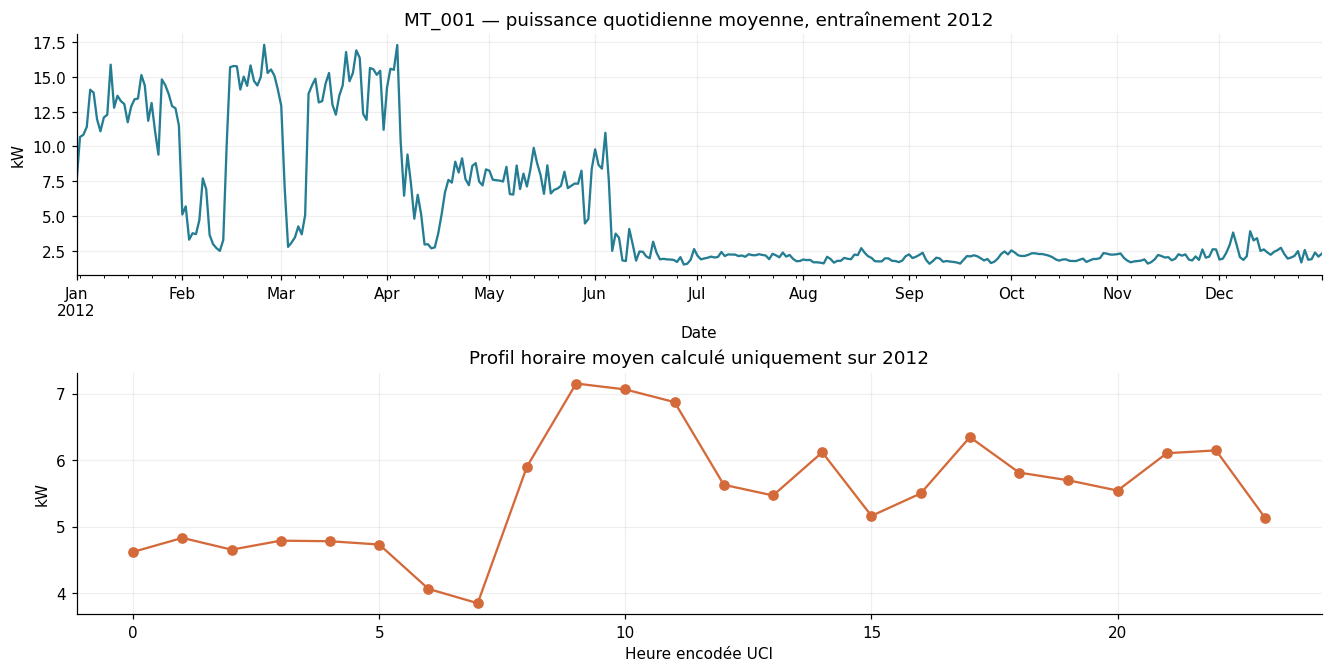

In [4]:
s=raw[CLIENT]
counts=s.resample('h',closed='right',label='left').count()
hourly=s.resample('h',closed='right',label='left').mean().where(counts==4).rename('charge_kW')
hourly=hourly.loc['2011':'2014'].asfreq('h')
assert hourly.notna().all(), 'Heures incomplètes : examiner les données avant les fenêtres.'
dst_days=[]
for year in range(2011,2015):
    for month in (3,10):
        dates=pd.date_range(f'{year}-{month:02d}-01',periods=calendar.monthrange(year,month)[1],freq='D')
        dst_days.append(dates[dates.dayofweek==6][-1])
dst_hours=hourly.index.normalize().isin(dst_days)
audit=pd.DataFrame(dict(n_heures=[len(hourly)],manquants=[int(hourly.isna().sum())],
                       zeros=[int(hourly.eq(0).sum())],jours_changement_heure=[len(dst_days)]))
display(audit)
hourly.to_csv(OUT/'charge_horaire_kW.csv',encoding='utf-8-sig')
audit.to_csv(OUT/'audit_donnees.csv',index=False)
fig,axes=plt.subplots(2,1,figsize=(12,6),constrained_layout=True)
hourly.loc['2012'].resample('D').mean().plot(ax=axes[0],color='#247d92')
axes[0].set(title=f'{CLIENT} — puissance quotidienne moyenne, entraînement 2012',ylabel='kW',xlabel='Date')
hourly.loc['2012'].groupby(hourly.loc['2012'].index.hour).mean().plot(ax=axes[1],marker='o',color='#d46a3a')
axes[1].set(title='Profil horaire moyen calculé uniquement sur 2012',ylabel='kW',xlabel='Heure encodée UCI')
savefig(fig,'01_exploration.png')


### 3. Fenêtres, normalisation et absence de fuite

À l'origine J à 00:00, l'entrée couvre les 168 intervalles horaires entièrement terminés
avant J ; les sorties couvrent J à 00:00 jusqu'à J à 23:00, soit H+1 à H+24.
Une seule émission par jour évite le chevauchement des cibles. L'historique peut venir
de l'année précédente, mais les **24 cibles restent dans leur ensemble**.

La moyenne et l'écart-type sont ajustés sur les heures de 2012 seulement. Les calendriers
passés et celui du jour cible sont connus sans consulter sa consommation. Le réseau
reçoit la charge et six composantes cycliques passées ; son état final est concaténé
aux quatre composantes du calendrier du jour cible. Ridge reçoit les 168 charges
normalisées et le même calendrier cible. Aucun modèle ne reçoit de consommation future.


In [5]:
train_hourly=hourly.loc['2012']
MU,SIGMA=float(train_hourly.mean()),float(train_hourly.std(ddof=0))
assert SIGMA>0
def cyclical(index):
    index=pd.DatetimeIndex(index)
    return np.column_stack([f(2*np.pi*v/period) for v,period in
                            [(index.hour,24),(index.dayofweek,7),(index.dayofyear-1,365.2425)]
                            for f in (np.sin,np.cos)]).astype('float32')

def make_windows(series,lookback=168):
    inputs=[]; contexts=[]; targets=[]; dates=[]; flags=[]; daily=[]; weekly=[]
    for day in pd.date_range('2012-01-01','2014-12-31',freq='D'):
        past=pd.date_range(day-pd.Timedelta(hours=lookback),periods=lookback,freq='h')
        future=pd.date_range(day,periods=24,freq='h')
        hist=series.reindex(past).to_numpy()
        y=series.reindex(future).to_numpy()
        b24=series.reindex(future-pd.Timedelta(days=1)).to_numpy()
        b168=series.reindex(future-pd.Timedelta(days=7)).to_numpy()
        if not np.isfinite(np.r_[hist,y,b24,b168]).all(): continue
        assert past.max()<future.min() and future.min().year==future.max().year
        inputs.append(np.column_stack([(hist-MU)/SIGMA,cyclical(past)]))
        contexts.append(cyclical([day])[0,2:])
        targets.append(y); dates.append(day); daily.append(b24);weekly.append(b168)
        full=pd.date_range(day-pd.Timedelta(hours=168),day+pd.Timedelta(hours=23),freq='h')
        flags.append(full.normalize().isin(dst_days).any())
    return dict(X=np.asarray(inputs,dtype='float32'),C=np.asarray(contexts,dtype='float32'),
                y=np.asarray(targets),dates=pd.DatetimeIndex(dates),dst=np.asarray(flags),
                daily=np.asarray(daily),weekly=np.asarray(weekly))

W=make_windows(hourly)
MASK={name:W['dates'].year==year for name,year in [('train',2012),('val',2013),('test',2014)]}
assert [int(MASK[k].sum()) for k in ('train','val','test')]==[366,365,365]
cut=pd.Timestamp('2013-06-01')
altered=hourly.copy();altered.loc[cut:]=1e9
W_alt=make_windows(altered)
safe=W['dates']<=cut
np.testing.assert_array_equal(W['X'][safe],W_alt['X'][safe])
np.testing.assert_array_equal(W['C'][safe],W_alt['C'][safe])
display(pd.DataFrame([dict(ensemble=k,n_jours=int(m.sum()),premiere_cible=str(W['dates'][m].min()),
                          derniere_cible=str(W['dates'][m].max()+pd.Timedelta(hours=23)),
                          jours_avec_effet_DST=int(W['dst'][m].sum())) for k,m in MASK.items()]))
print('Test causal réussi. Formes X / contexte / cibles :',W['X'].shape,W['C'].shape,W['y'].shape)
(OUT/'normalisation.json').write_text(json.dumps(dict(client=CLIENT,moyenne=MU,ecart_type=SIGMA,
                                                   ajustement='2012 uniquement'),indent=2),encoding='utf-8')


,ensemble,n_jours,premiere_cible,derniere_cible,jours_avec_effet_DST
0,train,366,2012-01-01 00:00:00,2012-12-31 23:00:00,16
1,val,365,2013-01-01 00:00:00,2013-12-31 23:00:00,16
2,test,365,2014-01-01 00:00:00,2014-12-31 23:00:00,16


Test causal réussi. Formes X / contexte / cibles : (1096, 168, 7) (1096, 4) (1096, 24)


126

### 4. Références et sélection de Ridge

Répéter le dernier jour ou la semaine précédente donne deux références utiles.
Pour Ridge, quatre régularisations fixées à l'avance sont comparées sur 2013 uniquement.
La sélection minimise la MAE dans l'unité d'origine. Le test 2014 ne sert à aucun choix.
Le modèle reste entraîné sur 2012, comme le LSTM, pour garder la même information d'apprentissage.


In [6]:
Xridge=np.column_stack([W['X'][:,:,0],W['C']])
ridge_trials=[]; ridge_models={}
with threadpool_limits(limits=2):
    for alpha in (1.,10.,100.,1000.):
        model=make_pipeline(StandardScaler(),Ridge(alpha=alpha))
        model.fit(Xridge[MASK['train']],W['y'][MASK['train']])
        p=np.maximum(model.predict(Xridge[MASK['val']]),0)
        ridge_trials.append(dict(alpha=alpha,**scores(W['y'][MASK['val']],p)))
        ridge_models[alpha]=model
ridge_trials=pd.DataFrame(ridge_trials)
BEST_ALPHA=float(ridge_trials.sort_values('MAE').iloc[0].alpha)
ridge=ridge_models[BEST_ALPHA]
display(ridge_trials)
ridge_trials.to_csv(OUT/'selection_ridge_validation.csv',index=False)


,alpha,MAE,RMSE,biais
0,1.0,3.814307,5.732314,-0.628860
1,10.0,3.048901,4.628881,-0.320243
2,100.0,2.600752,4.025453,-0.062921
3,1000.0,2.678191,4.139036,-0.031723


### 5. Comprendre et entraîner le LSTM

Un LSTM conserve un état qui évolue à chaque heure, avec des portes qui contrôlent
ce qu'il retient, ajoute ou transmet. Ici une couche de 32 unités lit l'historique
dans l'ordre. Une couche linéaire transforme l'état final et le calendrier cible
en **24 sorties directes**, sans réinjecter les prédictions dans le réseau.

La perte MSE porte sur les charges normalisées. Adam ajuste les poids ; les gradients
sont limités pour éviter les explosions. L'arrêt anticipé utilise uniquement la MSE
de validation 2013, avec restauration du meilleur état. Mélanger les journées de
l'entraînement est permis après le découpage ; l'ordre des heures dans chaque fenêtre
reste intact. Les graines sont fixées avant le test. Les sorties négatives éventuelles
sont ramenées à zéro pour tous les modèles de régression, règle physique fixée à l'avance.

Voir la [documentation officielle LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html).
La reproductibilité exacte peut varier selon les versions et le matériel.


In [7]:
class DemandLSTM(nn.Module):
    def __init__(self,hidden=32):
        super().__init__()
        self.lstm=nn.LSTM(input_size=7,hidden_size=hidden,batch_first=True)
        self.head=nn.Linear(hidden+4,24)
    def forward(self,x,context):
        _,(h,_) = self.lstm(x)
        return self.head(torch.cat([h[-1],context],dim=1))

def predict_network(model,windows,mask):
    model.eval()
    with torch.no_grad():
        p=model(torch.tensor(windows['X'][mask]),torch.tensor(windows['C'][mask])).numpy()
    return np.maximum(p*SIGMA+MU,0)

def train_network(windows,seed,label):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    model=DemandLSTM(CFG['hidden']).to(DEVICE)
    optimizer=torch.optim.Adam(model.parameters(),lr=CFG['learning_rate'],weight_decay=CFG['weight_decay'])
    trainmask=windows['dates'].year==2012;valmask=windows['dates'].year==2013
    data=TensorDataset(torch.tensor(windows['X'][trainmask]),torch.tensor(windows['C'][trainmask]),
                       torch.tensor((windows['y'][trainmask]-MU)/SIGMA,dtype=torch.float32))
    loader=DataLoader(data,batch_size=CFG['batch_size'],shuffle=True,
                      generator=torch.Generator().manual_seed(seed),num_workers=0)
    vx=torch.tensor(windows['X'][valmask]);vc=torch.tensor(windows['C'][valmask])
    vy=torch.tensor((windows['y'][valmask]-MU)/SIGMA,dtype=torch.float32)
    best=float('inf');best_state=None;stale=0;history=[];start=time.perf_counter()
    for epoch in range(1,CFG['epochs']+1):
        model.train();total=0
        for x,c,y in loader:
            optimizer.zero_grad();loss=nn.functional.mse_loss(model(x,c),y)
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.0);optimizer.step()
            total+=loss.item()*len(x)
        model.eval()
        with torch.no_grad(): val_loss=nn.functional.mse_loss(model(vx,vc),vy).item()
        history.append(dict(modele=label,graine=seed,epoch=epoch,MSE_train=total/len(data),MSE_val=val_loss))
        if val_loss<best-1e-6:
            best=val_loss;best_epoch=epoch;best_state=copy.deepcopy(model.state_dict());stale=0
        else: stale+=1
        if stale>=CFG['patience']: break
    assert best_state is not None
    model.load_state_dict(best_state)
    checkpoint=dict(state_dict=best_state,hidden=CFG['hidden'],lookback=int(windows['X'].shape[1]),
                    seed=seed,mean=MU,std=SIGMA,client=CLIENT,best_epoch=best_epoch,config=CFG)
    torch.save(checkpoint,OUT/f'{label}_seed{seed}.pt')
    info=dict(modele=label,graine=seed,meilleure_epoch=best_epoch,MSE_validation_normalisee=best,
              secondes=time.perf_counter()-start,parametres=sum(p.numel() for p in model.parameters()))
    print(label,seed,': meilleure époque',best_epoch,flush=True)
    return model,history,info

models={};histories=[];runs=[]
for seed in SEEDS:
    model,hist,info=train_network(W,seed,'LSTM_168h')
    models[seed]=model;histories.extend(hist);runs.append(info)
# Ablation fixée avant le test : même architecture et mêmes dates, historique de 24 h.
W24=make_windows(hourly,lookback=24)
assert W24['dates'].equals(W['dates'])
model24,hist,info=train_network(W24,42,'LSTM_24h')
histories.extend(hist);runs.append(info)
histories=pd.DataFrame(histories);runs=pd.DataFrame(runs)
display(runs)
histories.to_csv(OUT/'courbes_apprentissage.csv',index=False)
runs.to_csv(OUT/'entrainements.csv',index=False)


LSTM_168h 17 : meilleure époque 23


LSTM_168h 42 : meilleure époque 15


LSTM_168h 73 : meilleure époque 9


LSTM_24h 42 : meilleure époque 15


,modele,graine,meilleure_epoch,MSE_validation_normalisee,secondes,parametres
0,LSTM_168h,17,23,0.465890,40.028511,6136
1,LSTM_168h,42,15,0.475060,51.212615,6136
2,LSTM_168h,73,9,0.560365,45.588853,6136
3,LSTM_24h,42,15,0.479925,7.664737,6136


### 6. Évaluation hors échantillon : aucune sélection sur 2014

Les modèles sont figés avant cette cellule. L'ensemble LSTM est la moyenne des trois
réseaux ; il est défini à l'avance, sans choisir le meilleur sur le test. On rapporte
également chaque graine, leur moyenne et leur dispersion. MAE/RMSE sont en kW.
Les pointes sont définies par le 95e percentile de la charge **d'entraînement**.
Les scores mensuels décrivent les émissions successives de 2014, sans réentraînement
sur les observations du test. La MAPE est évitée à cause des faibles charges et des zéros.


In [8]:
testmask=MASK['test'];valmask=MASK['val'];Y=W['y'][testmask]
test_preds={'Persistance 24h':W['daily'][testmask],'Persistance 168h':W['weekly'][testmask],
            'Ridge':np.maximum(ridge.predict(Xridge[testmask]),0)}
for seed,model in models.items(): test_preds[f'LSTM 168h graine {seed}']=predict_network(model,W,testmask)
test_preds['LSTM ensemble']=np.mean([test_preds[f'LSTM 168h graine {s}'] for s in SEEDS],axis=0)
test_preds['LSTM 24h ablation']=predict_network(model24,W24,testmask)
PEAK=float(train_hourly.quantile(.95)); peakmask=Y>PEAK;clean=~W['dst'][testmask]
metric_rows=[];horizon_rows=[];prediction_rows=[]
reference_mae=scores(Y,test_preds['Persistance 168h'])['MAE']
for name,p in test_preds.items():
    assert p.shape==Y.shape and np.isfinite(p).all()
    row=dict(modele=name,**scores(Y,p),MAE_pointes=mean_absolute_error(Y[peakmask],p[peakmask]),
             MAE_hors_DST=mean_absolute_error(Y[clean].ravel(),p[clean].ravel()),
             n_pointes=int(peakmask.sum()),n_jours_hors_DST=int(clean.sum()))
    row['gain_MAE_vs_hebdo_pct']=100*(1-row['MAE']/reference_mae)
    metric_rows.append(row)
    for h in range(24): horizon_rows.append(dict(modele=name,horizon=h+1,**scores(Y[:,h],p[:,h])))
    for i,day in enumerate(W['dates'][testmask]):
        for h in range(24):
            prediction_rows.append(dict(modele=name,date_emission=day,date_cible=day+pd.Timedelta(hours=h),
                                        horizon=h+1,reel_kW=Y[i,h],prediction_kW=p[i,h],
                                        fenetre_DST=bool(W['dst'][testmask][i])))
metrics=pd.DataFrame(metric_rows);by_horizon=pd.DataFrame(horizon_rows);predictions=pd.DataFrame(prediction_rows)
display(metrics.round(4))
seed_metrics=metrics[metrics.modele.str.startswith('LSTM 168h graine')][['MAE','RMSE']].agg(['mean','std'])
display(seed_metrics.rename(index={'mean':'Moyenne des graines','std':'Écart-type des graines'}))
metrics.to_csv(OUT/'metriques_test_2014.csv',index=False)
by_horizon.to_csv(OUT/'metriques_par_horizon.csv',index=False)
predictions.to_csv(OUT/'predictions_test_2014.csv',index=False)
seed_metrics.to_csv(OUT/'variabilite_graines.csv')


,modele,MAE,RMSE,biais,MAE_pointes,MAE_hors_DST,n_pointes,n_jours_hors_DST,gain_MAE_vs_hebdo_pct
0,Persistance 24h,1.7473,4.0750,-0.0017,6.1929,1.7788,150,349,19.1913
1,Persistance 168h,2.1623,4.7128,-0.0028,8.1303,2.1977,150,349,0.0000
2,Ridge,2.0688,3.5555,0.1224,8.6506,2.1009,150,349,4.3245
3,LSTM 168h graine 17,1.8839,3.4836,-0.2246,9.6750,1.9130,150,349,12.8749
4,LSTM 168h graine 42,2.0904,3.5422,0.0390,9.9745,2.1232,150,349,3.3263
5,LSTM 168h graine 73,2.2571,3.8289,-0.1284,11.1129,2.2900,150,349,-4.3857
6,LSTM ensemble,2.0436,3.5629,-0.1046,10.2542,2.0746,150,349,5.4905
7,LSTM 24h ablation,2.1435,3.6238,-0.0265,10.1036,2.1785,150,349,0.8675


,MAE,RMSE
Moyenne des graines,2.077125,3.618226
Écart-type des graines,0.186964,0.184789


### 7. Graphiques et analyse des erreurs

La première semaine illustrée est fixée à l'avance (début juin). La semaine la plus
difficile est identifiée sur le test uniquement pour le diagnostic, sans réutiliser
cette information pour ajuster les modèles. L'axe horaire suit la convention UCI.


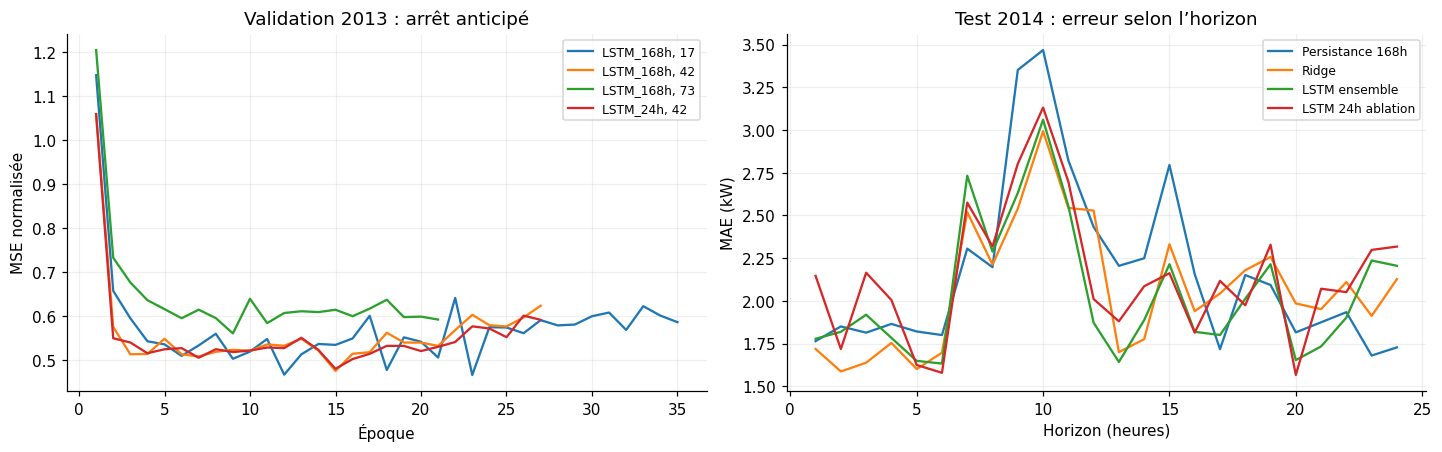

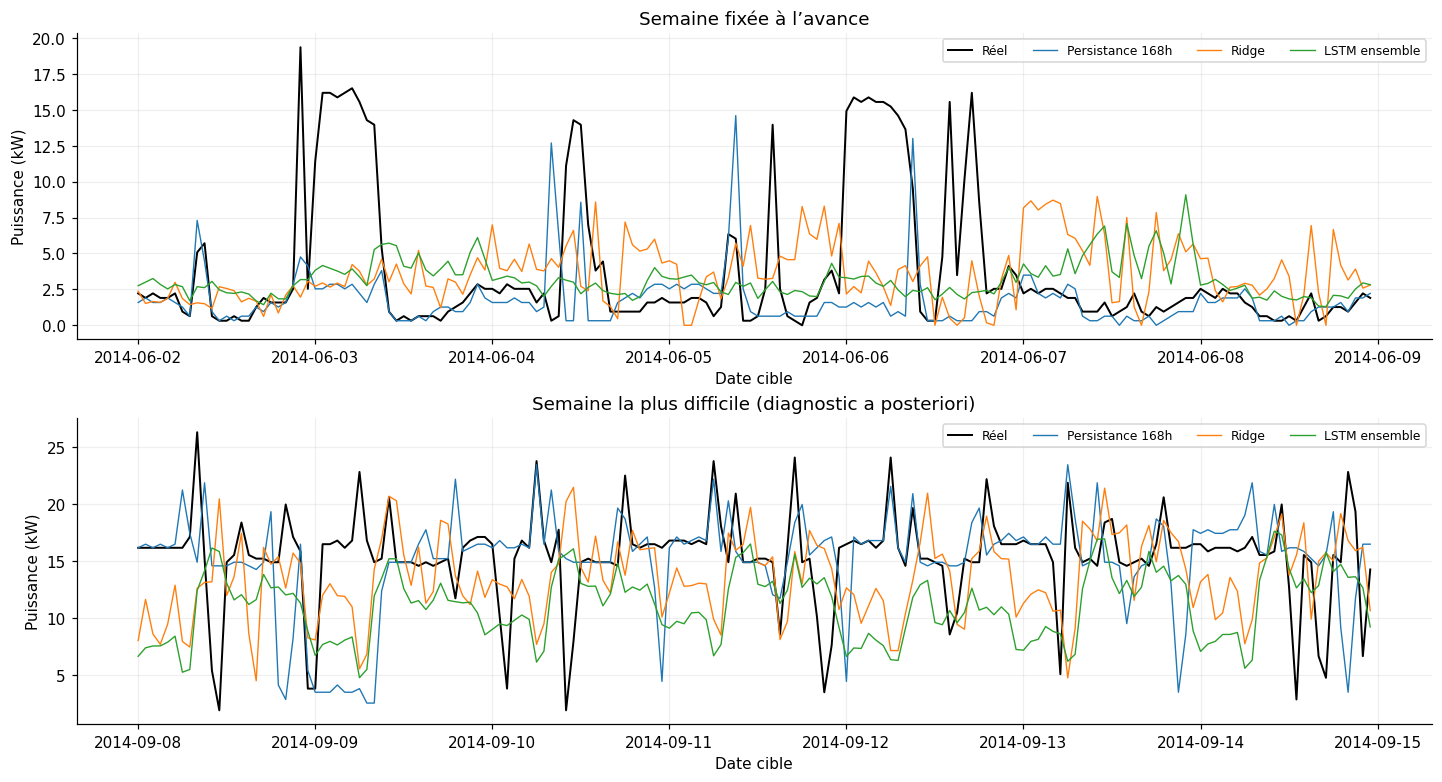

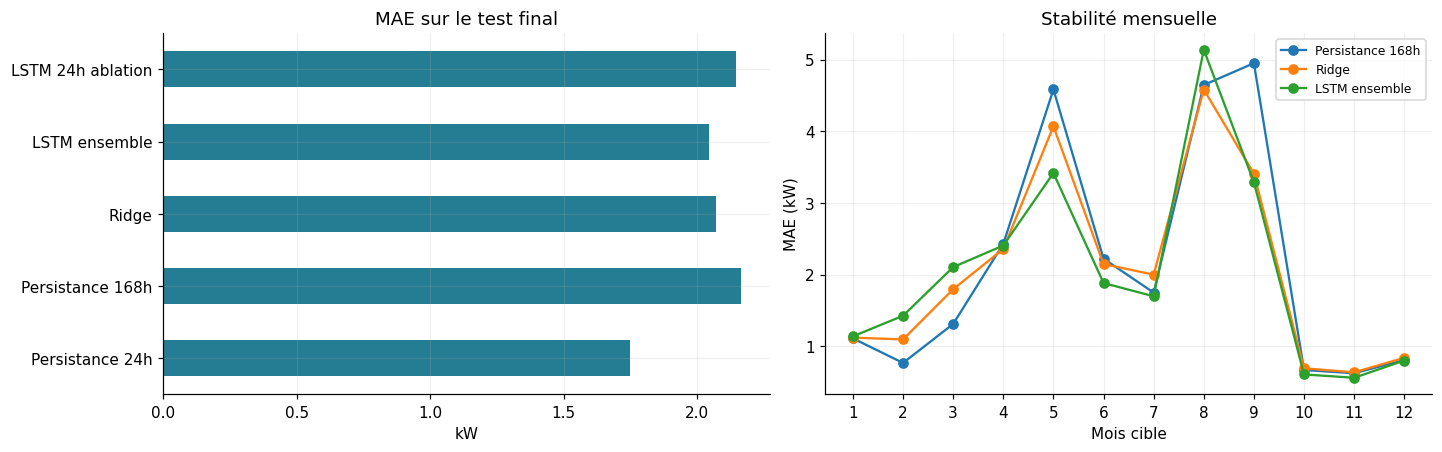

In [9]:
fig,axes=plt.subplots(1,2,figsize=(13,4),constrained_layout=True)
for (label,seed),g in histories.groupby(['modele','graine']):
    axes[0].plot(g.epoch,g.MSE_val,label=f'{label}, {seed}')
axes[0].set(title='Validation 2013 : arrêt anticipé',xlabel='Époque',ylabel='MSE normalisée')
axes[0].legend(fontsize=8)
for name in ('Persistance 168h','Ridge','LSTM ensemble','LSTM 24h ablation'):
    g=by_horizon[by_horizon.modele==name]
    axes[1].plot(g.horizon,g.MAE,label=name)
axes[1].set(title='Test 2014 : erreur selon l’horizon',xlabel='Horizon (heures)',ylabel='MAE (kW)')
axes[1].legend(fontsize=8)
savefig(fig,'02_apprentissage_horizons.png')

ensemble=predictions[predictions.modele=='LSTM ensemble'].copy()
daily_error=(ensemble.reel_kW-ensemble.prediction_kW).abs().groupby(ensemble.date_emission).mean()
weekly_error=daily_error.resample('W-MON',closed='left',label='left').mean()
worst=weekly_error.idxmax()
fig,axes=plt.subplots(2,1,figsize=(13,7),constrained_layout=True)
for ax,start,title in zip(axes,[pd.Timestamp('2014-06-02'),worst],['Semaine fixée à l’avance','Semaine la plus difficile (diagnostic a posteriori)']):
    end=start+pd.Timedelta(days=7)
    observed=ensemble[ensemble.date_cible.between(start,end,inclusive='left')]
    ax.plot(observed.date_cible,observed.reel_kW,color='black',lw=1.3,label='Réel')
    for name in ('Persistance 168h','Ridge','LSTM ensemble'):
        g=predictions[(predictions.modele==name)&predictions.date_cible.between(start,end,inclusive='left')]
        ax.plot(g.date_cible,g.prediction_kW,lw=.9,label=name)
    ax.set(title=title,ylabel='Puissance (kW)',xlabel='Date cible');ax.legend(ncol=4,fontsize=8)
savefig(fig,'03_semaines_previsions.png')

monthly=[]
for (name,month),g in predictions.groupby(['modele',predictions.date_cible.dt.month]):
    monthly.append(dict(modele=name,mois=month,**scores(g.reel_kW,g.prediction_kW)))
monthly=pd.DataFrame(monthly);monthly.to_csv(OUT/'metriques_mensuelles.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(13,4),constrained_layout=True)
show=['Persistance 24h','Persistance 168h','Ridge','LSTM ensemble','LSTM 24h ablation']
metrics.set_index('modele').loc[show,'MAE'].plot.barh(ax=axes[0],color='#247d92')
axes[0].set(title='MAE sur le test final',xlabel='kW',ylabel='')
for name in ('Persistance 168h','Ridge','LSTM ensemble'):
    g=monthly[monthly.modele==name];axes[1].plot(g.mois,g.MAE,'o-',label=name)
axes[1].set(title='Stabilité mensuelle',xlabel='Mois cible',ylabel='MAE (kW)',xticks=range(1,13));axes[1].legend(fontsize=8)
savefig(fig,'04_comparaisons.png')


### 8. Recharger un checkpoint et émettre une prévision datée

Le checkpoint choisi est celui de la graine à la meilleure validation 2013, jamais
celui au meilleur test. On vérifie que sa recharge reproduit les sorties. L'exemple
prévoit le 1er janvier 2015 depuis les dernières heures de 2014 ; il utilise le modèle
figé de l'expérience, sans réentraînement final. Ce n'est pas une prévision actuelle.


In [10]:
best_run=runs[runs.modele=='LSTM_168h'].sort_values('MSE_validation_normalisee').iloc[0]
best_seed=int(best_run.graine)
checkpoint=torch.load(OUT/f'LSTM_168h_seed{best_seed}.pt',map_location='cpu',weights_only=True)
reloaded=DemandLSTM(checkpoint['hidden']);reloaded.load_state_dict(checkpoint['state_dict'])
np.testing.assert_allclose(predict_network(reloaded,W,testmask),test_preds[f'LSTM 168h graine {best_seed}'],rtol=1e-6)
origin=hourly.index.max()+pd.Timedelta(hours=1)
past=pd.date_range(origin-pd.Timedelta(hours=168),periods=168,freq='h')
x=np.column_stack([(hourly.reindex(past).to_numpy()-MU)/SIGMA,cyclical(past)]).astype('float32')
c=cyclical([origin])[:,2:]
reloaded.eval()
with torch.no_grad(): next_values=np.maximum(reloaded(torch.tensor(x[None]),torch.tensor(c)).numpy()[0]*SIGMA+MU,0)
future=pd.DataFrame(dict(date_emission=origin,date_cible=pd.date_range(origin,periods=24,freq='h'),
                         horizon=np.arange(1,25),prediction_kW=next_values))
display(future.round(3));future.to_csv(OUT/'prevision_2015_01_01.csv',index=False)
config=dict(client=CLIENT,normalisation=dict(mean=MU,std=SIGMA),seeds=SEEDS,config=CFG,
            best_ridge_alpha=BEST_ALPHA,selected_seed=best_seed,versions=versions,
            source_sha256=sha256(subset),peak_threshold_kW=PEAK,
            train='2012',validation='2013',test='2014',executed_at_utc=datetime.now(timezone.utc).isoformat())
(OUT/'configuration.json').write_text(json.dumps(config,indent=2),encoding='utf-8')
best=metrics.sort_values('MAE').iloc[0];r=metrics.set_index('modele').loc['LSTM ensemble']
summary=(f'## Résultats mesurés — client {CLIENT}\n\n'
         f'LSTM ensemble : MAE **{r.MAE:.3f} kW**, RMSE **{r.RMSE:.3f} kW**, '
         f'gain MAE contre la persistance hebdomadaire **{r.gain_MAE_vs_hebdo_pct:+.1f} %**. '
         f'Meilleure MAE parmi les modèles testés : **{best.modele}**, {best.MAE:.3f} kW.\n\n'
         'Les trois graines et l’ablation sont présentées sans sélection sur le test. '
         'La comparaison porte sur un seul client, une année de test et un petit réseau ; '
         'elle ne prouve pas une supériorité générale du deep learning. '
         'Les mesures de changement d’heure encodées par UCI nécessitent la sensibilité fournie.')
display(Markdown(summary));(OUT/'synthese.md').write_text(summary,encoding='utf-8')
assert not predictions.duplicated(['modele','date_cible']).any()
print('Contrôles finaux réussis : cibles, causalité, dimensions, sorties finies et recharge du modèle.')


[environnement Python]:14: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(future.round(3));future.to_csv(OUT/'prevision_2015_01_01.csv',index=False)


,date_emission,date_cible,horizon,prediction_kW
0,2015-01-01,2015-01-01 00:00:00,1,1.732
1,2015-01-01,2015-01-01 01:00:00,2,1.833
2,2015-01-01,2015-01-01 02:00:00,3,1.916
3,2015-01-01,2015-01-01 03:00:00,4,2.111
4,2015-01-01,2015-01-01 04:00:00,5,2.434
5,2015-01-01,2015-01-01 05:00:00,6,1.892
6,2015-01-01,2015-01-01 06:00:00,7,2.001
7,2015-01-01,2015-01-01 07:00:00,8,1.851
8,2015-01-01,2015-01-01 08:00:00,9,2.469
9,2015-01-01,2015-01-01 09:00:00,10,4.426


## Résultats mesurés — client MT_001

LSTM ensemble : MAE **2.044 kW**, RMSE **3.563 kW**, gain MAE contre la persistance hebdomadaire **+5.5 %**. Meilleure MAE parmi les modèles testés : **Persistance 24h**, 1.747 kW.

Les trois graines et l’ablation sont présentées sans sélection sur le test. La comparaison porte sur un seul client, une année de test et un petit réseau ; elle ne prouve pas une supériorité générale du deep learning. Les mesures de changement d’heure encodées par UCI nécessitent la sensibilité fournie.

Contrôles finaux réussis : cibles, causalité, dimensions, sorties finies et recharge du modèle.


### 9. Livrables et prolongements

Les CSV permettent de recalculer tous les scores ; les fichiers `.pt` contiennent les
poids, l'architecture et la normalisation. Les quatre figures sont également intégrées
au notebook. Ne charger que des checkpoints de confiance. Pour étendre l'étude :
évaluer d'autres clients sélectionnés sur leur historique, augmenter le nombre d'années
d'entraînement, tester des quantiles avec une perte pinball et conserver un nouveau
test fermé. Une architecture plus complexe n'est pas automatiquement meilleure.

**Sources officielles consultées le 22 octobre 2026 :**
[UCI et licence](https://archive.ics.uci.edu/dataset/321/electricityloaddiagrams20112014),
[PyTorch LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html),
[reproductibilité PyTorch](https://docs.pytorch.org/docs/stable/notes/randomness.html).
